In [1]:
import pandas as pd
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import LabelEncoder

In [2]:
df = pd.read_csv('Iris.csv')
df = df.drop(columns=['Id'])
df

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Iris-virginica
146,6.3,2.5,5.0,1.9,Iris-virginica
147,6.5,3.0,5.2,2.0,Iris-virginica
148,6.2,3.4,5.4,2.3,Iris-virginica


In [3]:
le = LabelEncoder()
df_enc = df.copy()
df_enc['Species'] = le.fit_transform(df['Species'])

In [4]:
x = df_enc.drop(columns=['Species'])
y = df_enc['Species']

model = GaussianNB()
model.fit(x, y)

GaussianNB()

In [5]:
# [SepalLength, SepalWidth, PetalLength, PetalWidth]
test = [
    [5.1, 3.5, 1.4, 0.2],
    [6.0, 2.9, 4.5, 1.5],
    [6.9, 3.1, 5.4, 2.1]
]

print("\n----prediction------------------------")
for t in test:
    row = pd.DataFrame([t], columns=x.columns)
    pred = le.inverse_transform(model.predict(row))[0]
    prob = model.predict_proba(row)[0]
    print(f"Input: SepalLength={t[0]}, SepalWidth={t[1]}, PetalLength={t[2]}, PetalWidth={t[3]}")
    print(f"Result: Species -> {pred}")
    for cls, p in zip(le.classes_, prob):
        print(f"p({cls}) = {p:.4f}")
    print()


----prediction------------------------
Input: SepalLength=5.1, SepalWidth=3.5, PetalLength=1.4, PetalWidth=0.2
Result: Species -> Iris-setosa
p(Iris-setosa) = 1.0000
p(Iris-versicolor) = 0.0000
p(Iris-virginica) = 0.0000

Input: SepalLength=6.0, SepalWidth=2.9, PetalLength=4.5, PetalWidth=1.5
Result: Species -> Iris-versicolor
p(Iris-setosa) = 0.0000
p(Iris-versicolor) = 0.9865
p(Iris-virginica) = 0.0135

Input: SepalLength=6.9, SepalWidth=3.1, PetalLength=5.4, PetalWidth=2.1
Result: Species -> Iris-virginica
p(Iris-setosa) = 0.0000
p(Iris-versicolor) = 0.0000
p(Iris-virginica) = 1.0000



In [6]:
from sklearn.metrics import accuracy_score
y_pred = model.predict(x)
print(f"\nTraining Accuracy: {accuracy_score(y, y_pred)*100:.2f}%")


Training Accuracy: 96.00%


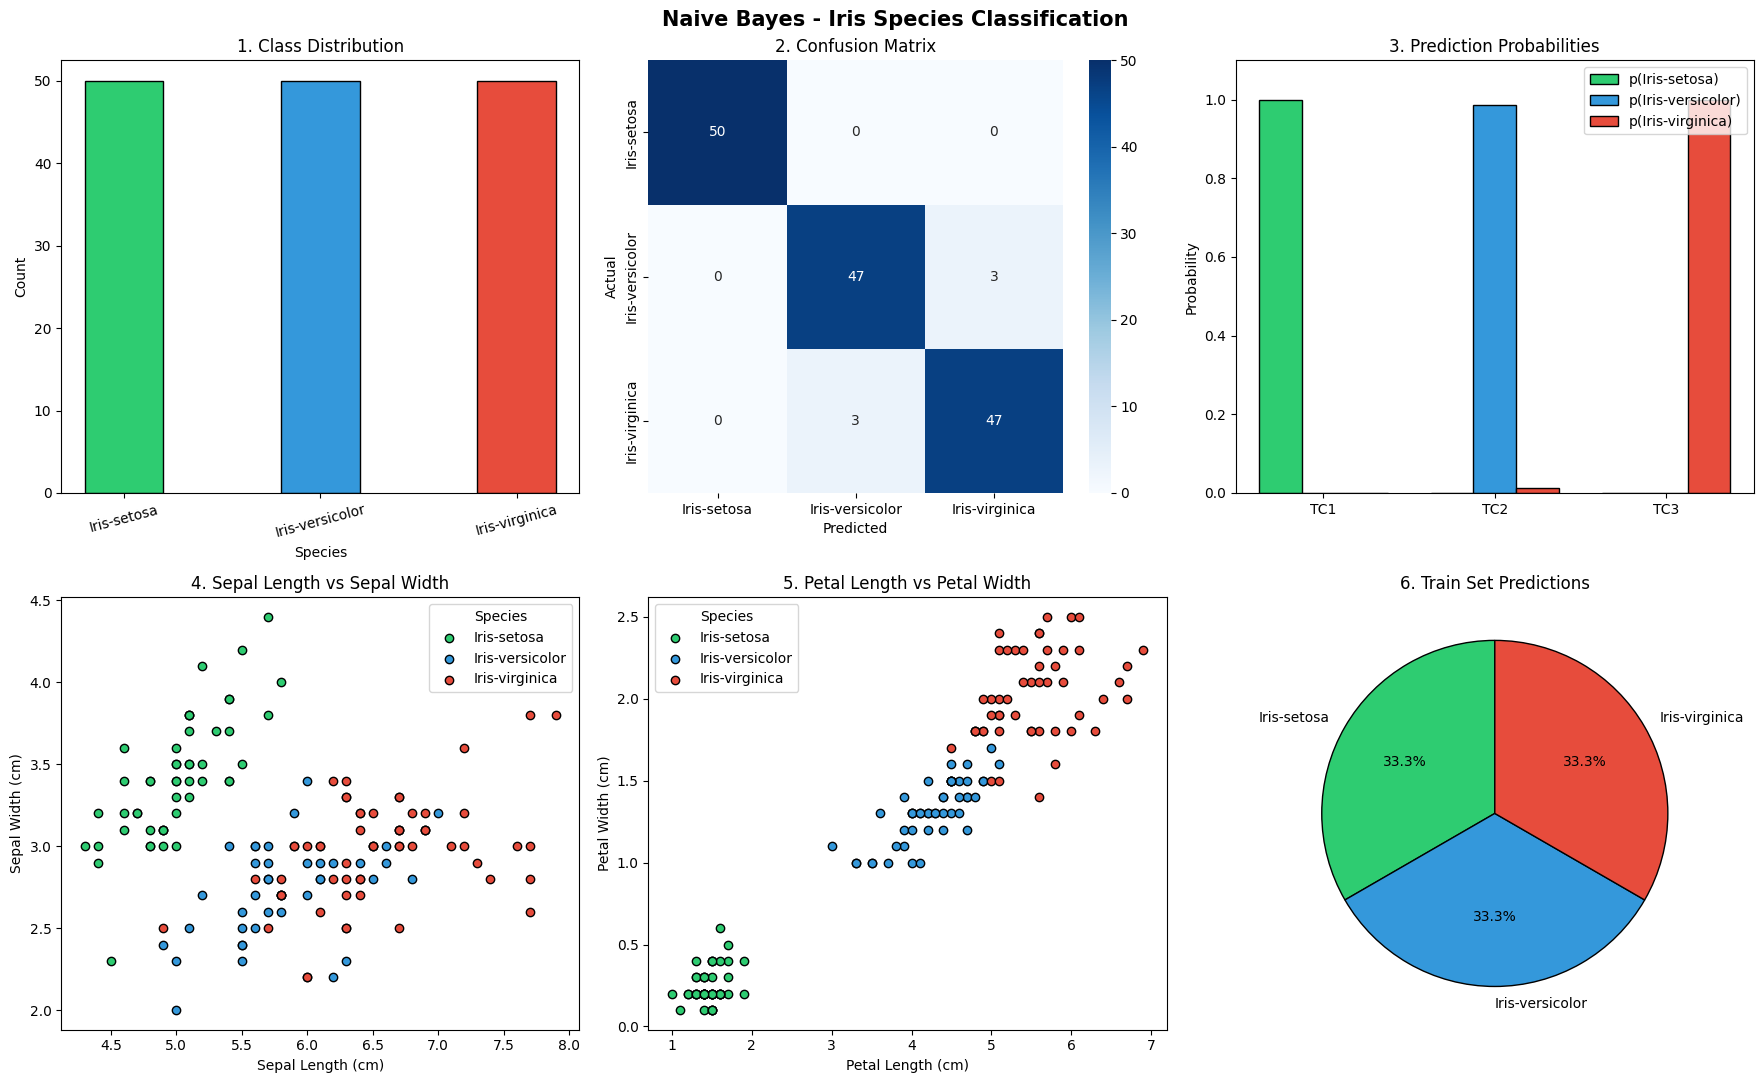

In [7]:
  import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle("Naive Bayes - Iris Species Classification", fontsize=15, fontweight="bold")

# 1. Class Distribution
counts = df['Species'].value_counts()
axes[0,0].bar(counts.index, counts.values, color=['#2ecc71', '#3498db', '#e74c3c'],
              edgecolor='black', width=0.4)
axes[0,0].set_title("1. Class Distribution")
axes[0,0].set_xlabel("Species")
axes[0,0].set_ylabel("Count")
axes[0,0].tick_params(axis='x', rotation=15)

# 2. Confusion Matrix
cm = confusion_matrix(y, y_pred)
sns.heatmap(cm, annot=True, cmap='Blues', fmt='g', ax=axes[0,1],
            xticklabels=le.classes_, yticklabels=le.classes_)
axes[0,1].set_title("2. Confusion Matrix")
axes[0,1].set_xlabel("Predicted")
axes[0,1].set_ylabel("Actual")

# 3. Prediction Probabilities
tc_labels = [f"TC{i+1}" for i in range(len(test))]
x_axis = np.arange(len(tc_labels))
width = 0.25
probs = np.array([model.predict_proba(pd.DataFrame([t], columns=x.columns))[0] for t in test])

colors = ['#2ecc71', '#3498db', '#e74c3c']
for i, cls in enumerate(le.classes_):
    axes[0,2].bar(x_axis + (i-1)*width, probs[:, i], width,
                  label=f'p({cls})', color=colors[i], edgecolor='black')
axes[0,2].set_title("3. Prediction Probabilities")
axes[0,2].set_xticks(x_axis)
axes[0,2].set_xticklabels(tc_labels)
axes[0,2].set_ylabel("Probability")
axes[0,2].set_ylim(0, 1.1)
axes[0,2].legend()

# 4. Sepal Length vs Sepal Width
for sp, c in zip(le.classes_, colors):
    s = df[df['Species'] == sp]
    axes[1,0].scatter(s['SepalLengthCm'], s['SepalWidthCm'], label=sp, color=c, edgecolor='black')
axes[1,0].set_title("4. Sepal Length vs Sepal Width")
axes[1,0].set_xlabel("Sepal Length (cm)")
axes[1,0].set_ylabel("Sepal Width (cm)")
axes[1,0].legend(title="Species")

# 5. Petal Length vs Petal Width
for sp, c in zip(le.classes_, colors):
    s = df[df['Species'] == sp]
    axes[1,1].scatter(s['PetalLengthCm'], s['PetalWidthCm'], label=sp, color=c, edgecolor='black')
axes[1,1].set_title("5. Petal Length vs Petal Width")
axes[1,1].set_xlabel("Petal Length (cm)")
axes[1,1].set_ylabel("Petal Width (cm)")
axes[1,1].legend(title="Species")

# 6. Pie Chart
pred_counts = pd.Series(y_pred).value_counts().sort_index()
pred_counts.index = le.inverse_transform(pred_counts.index)
axes[1,2].pie(pred_counts, labels=pred_counts.index, colors=colors,
              autopct='%1.1f%%', startangle=90, wedgeprops={'edgecolor': 'black'})
axes[1,2].set_title("6. Train Set Predictions")

plt.tight_layout()
plt.show()